# Name: Asawari Ramesh Gaikwad
# Project Name: IPL Data Analysis
# Subject: DA

# Import The Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset

In [5]:
matches = pd.read_csv(r"C:\Users\Admin\Downloads\archive\matches.csv")
deliveries = pd.read_csv(r"C:\Users\Admin\Downloads\archive\deliveries.csv")
matches.head()

,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


# Data Cleaning & Preprocessing

In [6]:
matches.shape

(1095, 20)

In [7]:
deliveries.shape

(260920, 17)

In [8]:
matches.isnull().sum()

id                    0
season                0
city                 51
date                  0
match_type            0
player_of_match       5
venue                 0
team1                 0
team2                 0
toss_winner           0
toss_decision         0
winner                5
result                0
result_margin        19
target_runs           3
target_overs          3
super_over            0
method             1074
umpire1               0
umpire2               0
dtype: int64

In [9]:
deliveries.isnull().sum()

match_id                 0
inning                   0
batting_team             0
bowling_team             0
over                     0
ball                     0
batter                   0
bowler                   0
non_striker              0
batsman_runs             0
extra_runs               0
total_runs               0
extras_type         246795
is_wicket                0
player_dismissed    247970
dismissal_kind      247970
fielder             251566
dtype: int64

In [10]:
matches.duplicated().sum
deliveries.duplicated().sum()

np.int64(0)

# Data Overview & Inspection

In [11]:
# Check the number of rows and columns in both datasets
print("Matches dataset shape:", matches.shape)
print("Deliveries dataset shape:", deliveries.shape)

# Display summary information and data types
matches.info()

Matches dataset shape: (1095, 20)
Deliveries dataset shape: (260920, 17)
<class 'pandas.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1095 non-null   int64  
 1   season           1095 non-null   str    
 2   city             1044 non-null   str    
 3   date             1095 non-null   str    
 4   match_type       1095 non-null   str    
 5   player_of_match  1090 non-null   str    
 6   venue            1095 non-null   str    
 7   team1            1095 non-null   str    
 8   team2            1095 non-null   str    
 9   toss_winner      1095 non-null   str    
 10  toss_decision    1095 non-null   str    
 11  winner           1090 non-null   str    
 12  result           1095 non-null   str    
 13  result_margin    1076 non-null   float64
 14  target_runs      1092 non-null   float64
 15  target_overs     1092 non-null   float64
 16

# Data Handling & Missing Values

In [12]:
# Standardize old team names to current team names
matches.replace({
    'Delhi Daredevils': 'Delhi Capitals',
    'Kings XI Punjab': 'Punjab Kings',
    'Rising Pune Supergiants': 'Rising Pune Supergiant',
    'Deccan Chargers': 'Sunrisers Hyderabad',
    'Royal Challengers Bangalore': 'Royal Challengers Bengaluru'
}, inplace=True)

# Check for missing values
print(matches.isnull().sum())

# Fill missing values in 'winner' and 'player_of_match' columns
matches['winner'] = matches['winner'].fillna('No Result')
matches['player_of_match'] = matches['player_of_match'].fillna('None')

# Check for duplicate rows
print("Duplicate rows:", matches.duplicated().sum())

id                    0
season                0
city                 51
date                  0
match_type            0
player_of_match       5
venue                 0
team1                 0
team2                 0
toss_winner           0
toss_decision         0
winner                5
result                0
result_margin        19
target_runs           3
target_overs          3
super_over            0
method             1074
umpire1               0
umpire2               0
dtype: int64
Duplicate rows: 0


# Statistical Summary & Toss Impact Analysis

In [13]:
# Statistical summary of win margins
print(matches[['result_margin']].describe())

# Total number of seasons played
print("Total Seasons:", matches['season'].nunique())

# Calculate percentage of matches won by the toss-winning team
toss_match_win = matches[matches['toss_winner'] == matches['winner']]
win_percentage = (len(toss_match_win) / len(matches)) * 100
print(f"Win percentage after winning the toss: {win_percentage:.2f}%")

# Top 5 cities hosting the most IPL matches
print("\nTop 5 Cities hosting IPL matches:")
print(matches['city'].value_counts().head(5))

       result_margin
count    1076.000000
mean       17.259294
std        21.787444
min         1.000000
25%         6.000000
50%         8.000000
75%        20.000000
max       146.000000
Total Seasons: 17
Win percentage after winning the toss: 50.59%

Top 5 Cities hosting IPL matches:
city
Mumbai       173
Kolkata       93
Delhi         90
Chennai       85
Hyderabad     77
Name: count, dtype: int64


# Team Win Percentage Analysis

In [23]:
total_matches = matches['team1'].value_counts() + matches['team2'].value_counts()
wins = matches['winner'].value_counts()

win_pct = (wins / total_matches) * 100
print(win_pct.sort_values(ascending=False).dropna().round(2))

winner
Gujarat Titans                 62.22
Chennai Super Kings            57.98
Mumbai Indians                 55.17
Lucknow Super Giants           54.55
Kolkata Knight Riders          52.19
Rajasthan Royals               50.68
Rising Pune Supergiant         50.00
Royal Challengers Bengaluru    48.24
Delhi Capitals                 45.63
Punjab Kings                   45.53
Sunrisers Hyderabad            45.53
Gujarat Lions                  43.33
Kochi Tuskers Kerala           42.86
Pune Warriors                  26.09
Name: count, dtype: float64


# Top 10 Economical Bowlers

In [24]:
# Group runs conceded and balls bowled by bowler
runs_given = deliveries.groupby('bowler')['total_runs'].sum()
balls_bowled = deliveries.groupby('bowler')['total_runs'].count()

# Calculate Economy Rate (Runs per Over) for bowlers with 1000+ balls
economy = runs_given[balls_bowled >= 1000] / (balls_bowled[balls_bowled >= 1000] / 6)
print(economy.sort_values(ascending=True).head(10).round(2))

bowler
M Muralitharan     6.70
SP Narine          6.76
DW Steyn           6.79
Rashid Khan        6.91
R Ashwin           6.97
SL Malinga         7.03
Harbhajan Singh    7.04
SK Warne           7.19
M Kartik           7.20
JJ Bumrah          7.23
Name: total_runs, dtype: float64


# Top 10 Batters by Strike Rate

In [27]:
# Group runs and balls by batter
runs = deliveries.groupby('batter')['batsman_runs'].sum()
balls = deliveries.groupby('batter')['batsman_runs'].count()

# Calculate Strike Rate for players with 1000+ balls
sr = (runs[balls >= 1000] / balls[balls >= 1000]) * 100
print(sr.sort_values(ascending=False).head(10).round(2))

batter
AD Russell        164.22
N Pooran          154.77
GJ Maxwell        150.49
V Sehwag          148.83
AB de Villiers    148.58
YBK Jaiswal       146.76
RR Pant           143.60
PP Shaw           143.22
SA Yadav          142.51
JC Buttler        142.24
Name: batsman_runs, dtype: float64


# Exploratory Data Visualizations ( Charts & Graphs )

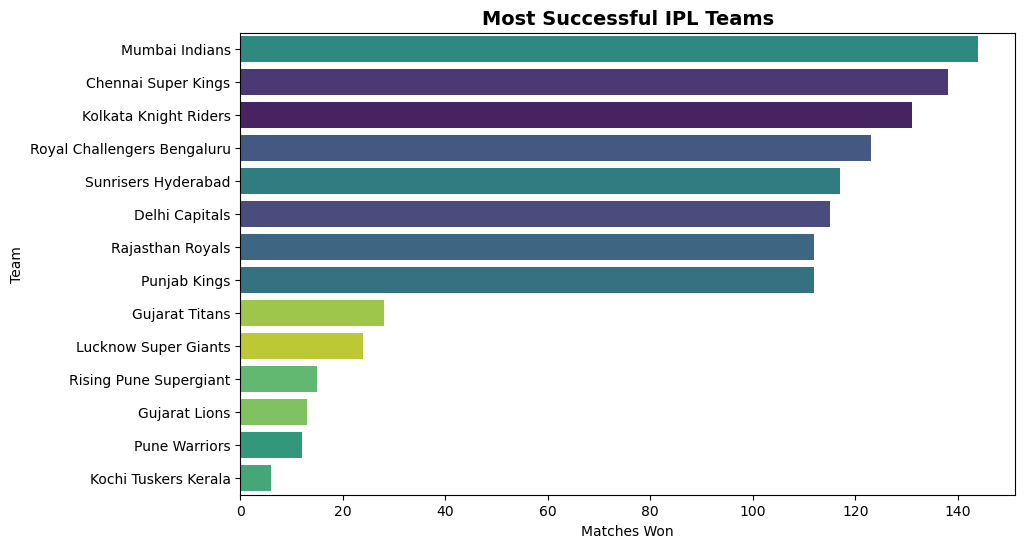

In [16]:
plt.figure(figsize=(10, 6))
sns.countplot(y='winner', hue='winner', data=matches[matches['winner'] != 'No Result'], 
              order=matches[matches['winner'] != 'No Result']['winner'].value_counts().index, 
              palette='viridis', legend=False)
plt.title('Most Successful IPL Teams', fontsize=14, fontweight='bold')
plt.xlabel('Matches Won')
plt.ylabel('Team')
plt.show()

# Univariate Analysis

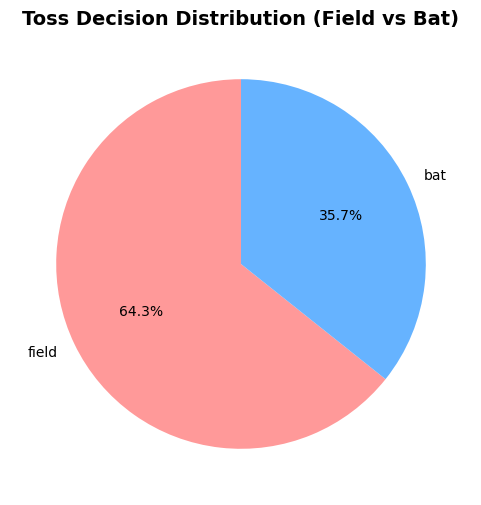

In [17]:
plt.figure(figsize=(6, 6))
toss_decision = matches['toss_decision'].value_counts()
plt.pie(toss_decision, labels=toss_decision.index, autopct='%1.1f%%', startangle=90, colors=['#ff9999', '#66b3ff'])
plt.title('Toss Decision Distribution (Field vs Bat)', fontsize=14, fontweight='bold')
plt.show()

# Bivariate Analysis

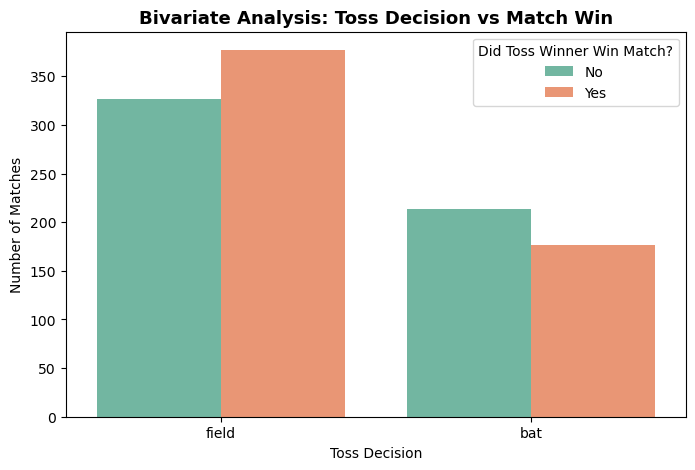

In [29]:
matches['Toss_Winner_Won'] = np.where(matches['toss_winner'] == matches['winner'], 'Yes', 'No')

plt.figure(figsize=(8, 5))
sns.countplot(x='toss_decision', hue='Toss_Winner_Won', data=matches, palette='Set2')
plt.title('Bivariate Analysis: Toss Decision vs Match Win', fontsize=13, fontweight='bold')
plt.xlabel('Toss Decision')
plt.ylabel('Number of Matches')
plt.legend(title='Did Toss Winner Win Match?')
plt.show()

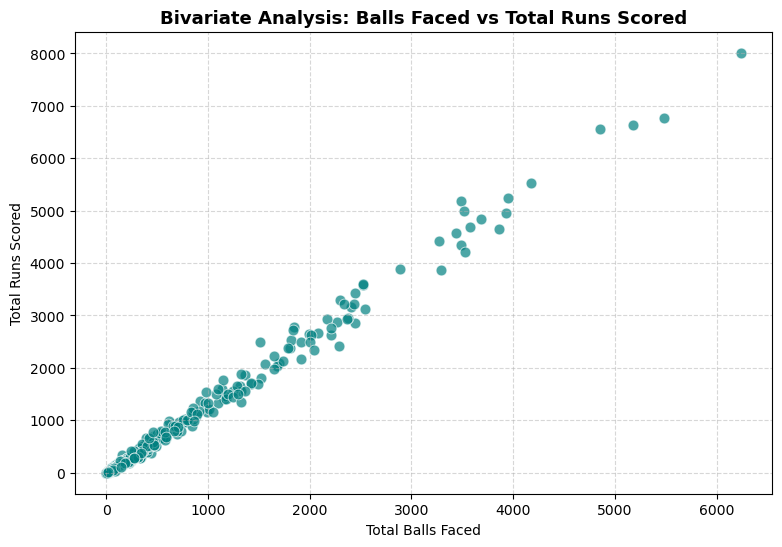

In [30]:
batter_summary = deliveries.groupby('batter').agg(
    Total_Runs=('batsman_runs', 'sum'),
    Balls_Faced=('batsman_runs', 'count')
).reset_index()

plt.figure(figsize=(9, 6))
sns.scatterplot(x='Balls_Faced', y='Total_Runs', data=batter_summary, color='teal', alpha=0.7, s=60)
plt.title('Bivariate Analysis: Balls Faced vs Total Runs Scored', fontsize=13, fontweight='bold')
plt.xlabel('Total Balls Faced')
plt.ylabel('Total Runs Scored')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Multivariate Analysis

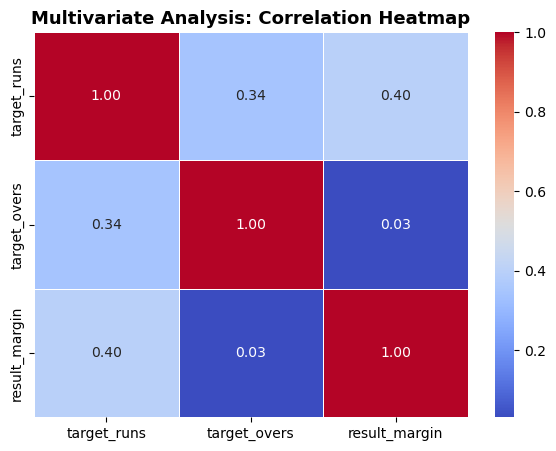

In [31]:
num_cols = matches[['target_runs', 'target_overs', 'result_margin']].dropna()

plt.figure(figsize=(7, 5))
sns.heatmap(num_cols.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Multivariate Analysis: Correlation Heatmap', fontsize=13, fontweight='bold')
plt.show()

## Key Insights & Conclusion

* **Franchise Dominance & Consistency:** Mumbai Indians and Chennai Super Kings lead the tournament in total wins, while Gujarat Titans holds the highest overall win percentage.
* **Toss & Chasing Advantage:** Captains winning the toss overwhelmingly prefer to field first, as chasing targets has proven to be a statistically stronger strategy (over 50% win rate).
* **Batting Performance:** Virat Kohli, Shikhar Dhawan, and Rohit Sharma lead the all-time run charts, while power-hitters dominate strike rates among batters facing over 1,000 deliveries.
* **Bowling Economy:** Muttiah Muralitharan, Sunil Narine, and Rashid Khan rank among the most economical bowlers in IPL history (minimum 1,000 balls bowled), highlighting the crucial role of spin in restricting runs.
* **Impact Players:** AB de Villiers and Chris Gayle hold the highest number of 'Player of the Match' awards, proving their single-handed match-winning impact.